# Dense Knowledge Representation
**CLIP vs. Qwen3-VL embeddings**  
**Longho Bernard Che**

This notebook compares two embedding architectures on **96 MMEB queries** across four
task categories. It includes the completed A100 run, aggregate results, query-modality
ablations, and five visually reviewed failure cases.

**Reproduce:** Open in Colab, select a CUDA GPU, and run the cells in order. Data and
results persist in `/content/drive/MyDrive/mmeb_analysis`. Public Hugging Face downloads
use `token=False`. Implementation cells are folded for easier reading.

Saved experimental outputs are preserved; this presentation cleanup did not rerun the
models. The written interpretations refer to the recorded configuration and selected cases.

## 1. Method

| Task | Dataset | Queries | Candidates per query |
|---|---|---:|---:|
| Image classification | CIFAR-100 | 24 | 32 |
| Composed image retrieval | CIRR | 24 | 32 |
| Visual question answering | TextVQA | 24 | 32 |
| Object-crop grounding | RefCOCO | 24 | 32 |

With seed **6938**, sample test rows without replacement. Retain each row's annotated
positive, deduplicate exact text/image pairs, sample 31 negatives, and shuffle the candidate
order. Both models receive the same inputs. Remove MMEB image markers but retain its text.

**CLIP ViT-B/32:** Encode image and text independently, normalize each vector, average them
when both modalities are present, and renormalize. This is an explicit late-fusion baseline.
**Qwen3-VL-Embedding-2B:** Jointly encode the modalities within each input using the official
wrapper, then pool and normalize the last non-padding token. Both models encode queries
and candidates separately and rank by cosine similarity.

Report top-1 accuracy and mean reciprocal rank (MRR). Image-only and text-only ablations
remove a query modality while keeping candidates fixed. Results describe sampled candidate
pools, not the full benchmark. RefCOCO measures crop retrieval, not bounding-box IoU.

## 2. Setup and data

In [ ]:
#@title Install dependencies
!pip -q install "transformers==4.57.6" "qwen-vl-utils==0.0.14" "accelerate>=1.12,<2" "datasets>=4.4,<5" "huggingface-hub>=0.34,<1" "fsspec[http]" pandas matplotlib pillow

In [2]:
#@title Imports and file utilities
import gc
import hashlib
import importlib.util
import importlib.metadata
import json
import platform
import re
import sys
import textwrap
import time
import zipfile
from pathlib import Path, PurePosixPath
from urllib.request import urlopen

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from datasets import load_dataset
# All repositories used here are public. Explicit token=False on download/model calls
# avoids Colab Secrets lookups; an HF_TOKEN secret is not required.
from huggingface_hub import hf_hub_download, hf_hub_url, snapshot_download
from tqdm.auto import tqdm

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()

def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2), encoding='utf-8')
    temporary.replace(path)

In [3]:
#@title Experiment configuration and Google Drive
SEED = 6938
N_QUERIES = 24
MAX_CANDIDATES = 32  # None = all unique original candidates; slower, especially for images.
N_FAILURE_CASES = 5
CLIP_BATCH_SIZE = 32
QWEN_BATCH_SIZE = 1
QWEN_MAX_PIXELS = 256 * 32 * 32  # At most ~256 visual tokens, subject to resizing rules.
QWEN_MAX_LENGTH = 2048

# Persist data, checkpoints, model downloads, and reports in the requested Drive folder.
WORK_DIR = Path('/content/drive/MyDrive/mmeb_analysis')
if not Path('/content/drive/MyDrive').is_dir():
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError('Open this notebook in Colab to use the configured Google Drive path.') from exc
    drive.mount('/content/drive')
WORK_DIR.mkdir(parents=True, exist_ok=True)
HUB_CACHE = WORK_DIR / 'hub_cache'
HUB_CACHE.mkdir(exist_ok=True)
DATASETS = {'IC': 'CIFAR-100', 'IR': 'CIRR', 'VQA': 'TextVQA', 'Grounding': 'RefCOCO'}
DATA_ID = 'TIGER-Lab/MMEB-eval'
DATA_REVISION = '2f069730be515ea60778413777816b53e2d2a697'
MODEL_IDS = {'clip': 'openai/clip-vit-base-patch32', 'qwen': 'Qwen/Qwen3-VL-Embedding-2B'}
MODEL_REVISIONS = {
    'clip': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268',
    'qwen': '9f2f7e710d6d81056aa5c0a4f04764fec6bb7bda',
}
QWEN_CODE_REVISION = '393e2978d27852b0d0230d6994f37f9c15bed73c'
PIPELINE_VERSION = '1.0'

assert N_QUERIES > 0
assert MAX_CANDIDATES is None or MAX_CANDIDATES >= 2
assert N_FAILURE_CASES >= 5
config = dict(seed=SEED, queries_per_dataset=N_QUERIES, max_candidates=MAX_CANDIDATES,
              datasets=DATASETS, data_revision=DATA_REVISION, model_ids=MODEL_IDS,
              model_revisions=MODEL_REVISIONS, qwen_code_revision=QWEN_CODE_REVISION,
              qwen_max_pixels=QWEN_MAX_PIXELS, qwen_max_length=QWEN_MAX_LENGTH,
              clip_fusion='normalized_equal_weight_mean', pipeline=PIPELINE_VERSION)
RUN_DIR = WORK_DIR / 'runs' / digest(config)[:12]
IMAGE_DIR = WORK_DIR / 'images' / DATA_REVISION[:12]
RUN_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
save_json(RUN_DIR / 'config.json', config)
print('Run directory:', RUN_DIR)

Mounted at /content/drive
Run directory: /content/drive/MyDrive/mmeb_analysis/runs/5dba0a76eb2a


In [4]:
#@title Load metadata and select matching queries/candidates
def clean_text(text):
    return re.sub(r'<\|image_\d+\|>', '', text or '').strip()

def make_item(text, image):
    item = {'text': clean_text(text), 'image': image or ''}
    if not item['text'] and not item['image']:
        raise ValueError('Encountered an empty MMEB input.')
    return item

def item_key(item):
    return (item['text'], item['image'])

def prepare_example(row, category, dataset, row_id):
    texts, images = row['tgt_text'], row['tgt_img_path']
    if len(texts) != len(images) or len(texts) < 2:
        raise ValueError(f'Invalid candidate lists: {dataset}:{row_id}')
    original = [make_item(t, i) for t, i in zip(texts, images)]
    # dict preserves order: the first unique item remains the annotated correct target.
    unique = list({item_key(x): x for x in original}.values())
    if len(unique) < 2:
        raise ValueError('Fewer than two distinct candidates.')
    rng = np.random.default_rng(int(digest([SEED, dataset, row_id])[:16], 16))
    count = len(unique) if MAX_CANDIDATES is None else min(MAX_CANDIDATES, len(unique))
    negatives = rng.choice(np.arange(1, len(unique)), size=count - 1, replace=False)
    selected = [unique[0]] + [unique[int(i)] for i in negatives]
    order = rng.permutation(count)
    candidates = [selected[int(i)] for i in order]
    gold = int(np.flatnonzero(order == 0)[0])
    assert item_key(candidates[gold]) == item_key(original[0])
    return dict(id=f'{dataset}:{row_id}', category=category, dataset=dataset, row_id=row_id,
                query=make_item(row['qry_text'], row['qry_img_path']), candidates=candidates,
                gold=gold, original_candidates=len(original), unique_candidates=len(unique))

examples, inspection = [], []
for category, dataset in DATASETS.items():
    metadata_path = hf_hub_download(DATA_ID, f'{dataset}/test-00000-of-00001.parquet',
                                    repo_type='dataset', revision=DATA_REVISION, cache_dir=HUB_CACHE, token=False)
    table = load_dataset('parquet', data_files=metadata_path, split='train',
                         cache_dir=str(WORK_DIR / 'datasets_cache'), token=False)
    required = {'qry_text', 'qry_img_path', 'tgt_text', 'tgt_img_path'}
    assert required.issubset(table.column_names), table.column_names
    if N_QUERIES > len(table):
        raise ValueError(f'{dataset} has only {len(table)} rows.')
    rng = np.random.default_rng(int(digest([SEED, dataset])[:16], 16))
    row_ids = sorted(rng.choice(len(table), N_QUERIES, replace=False).tolist())
    for row_id in row_ids:
        examples.append(prepare_example(table[row_id], category, dataset, row_id))
    first = table[row_ids[0]]
    inspection.append(dict(category=category, dataset=dataset, available_rows=len(table),
                           sampled_rows=len(row_ids), first_query=clean_text(first['qry_text']),
                           first_image=first['qry_img_path'],
                           original_candidates=len(first['tgt_text'])))

assert len({e['id'] for e in examples}) == len(examples)
save_json(RUN_DIR / 'sample_manifest.json', examples)
example_by_id = {e['id']: e for e in examples}
display(pd.DataFrame(inspection))
print('Sample manifest saved; every row includes the shuffled candidate list and gold index.')

,category,dataset,available_rows,sampled_rows,first_query,first_image,original_candidates
0,IC,CIFAR-100,1000,24,Represent the given image for classification,CIFAR-100/image_65.jpg,100
1,IR,CIRR,1000,24,"Given an image, find a similar everyday image ...",CIRR/dev-1032-3-img1.jpg,1000
2,VQA,TextVQA,1000,24,Represent the given image with the following q...,TextVQA/image_33.jpg,1000
3,Grounding,RefCOCO,1000,24,Select the portion of the image that follows t...,RefCOCO/image_1059389.jpg,1000


Sample manifest saved; every row includes the shuffled candidate list and gold index.


In [5]:
#@title Download and validate the selected images
def local_image_path(relative):
    parts = PurePosixPath(relative)
    if parts.is_absolute() or '..' in parts.parts or '\\' in relative:
        raise ValueError(f'Unsafe image path: {relative}')
    return IMAGE_DIR.joinpath(*parts.parts)

def fetch_images(required_images):
    missing = [p for p in sorted(set(required_images)) if not local_image_path(p).is_file()]
    if not missing:
        print('All selected images are cached.')
        return
    url = hf_hub_url(DATA_ID, 'images.zip', repo_type='dataset', revision=DATA_REVISION)
    total_bytes = 0
    try:
        with fsspec.open(url, 'rb', block_size=262144, cache_type='blockcache',
                         cache_options={'maxblocks': 64}) as remote:
            with zipfile.ZipFile(remote) as archive:
                # Validate every name before downloading, and read in archive order.
                members = [(name, archive.getinfo(name)) for name in missing]
                members.sort(key=lambda pair: pair[1].header_offset)
                for name, info in tqdm(members, desc='Extract selected images'):
                    blob = archive.read(info)  # ZipFile validates member CRC.
                    path = local_image_path(name)
                    path.parent.mkdir(parents=True, exist_ok=True)
                    temporary = path.with_suffix(path.suffix + '.tmp')
                    temporary.write_bytes(blob)
                    temporary.replace(path)
                    total_bytes += len(blob)
    except Exception as exc:
        raise RuntimeError('Selective image download failed. Rerun to resume cached files. '
                           'If this network blocks HTTP Range, use a network that supports it, '
                           'or manually extract the official images.zip into IMAGE_DIR.') from exc
    print(f'Saved {len(missing)} images ({total_bytes / 1e6:.1f} MB of image content).')

def read_image(relative):
    with Image.open(local_image_path(relative)) as image:
        return image.convert('RGB')

required_images = {item['image'] for e in examples for item in [e['query'], *e['candidates']]
                   if item['image']}
fetch_images(required_images)
for relative in tqdm(sorted(required_images), desc='Validate image decoding'):
    image = read_image(relative)
    assert image.width > 0 and image.height > 0
print(f'{len(examples)} queries; {len(required_images)} unique images verified.')

Saved 1478 images (24.1 MB of image content).


96 queries; 1478 unique images verified.


## 3. Encode and evaluate

The models run sequentially, with resumable embedding caches. Qwen uses a bounded image
resolution and batch size 1; CLIP text truncation is recorded. The environment and fixed
model/data revisions are retained for reproducibility.

In [7]:
#@title Runtime and package versions
import torch
import torch.nn.functional as F
from transformers import CLIPModel, CLIPProcessor

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(SEED)
if DEVICE == 'cuda':
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No CUDA GPU detected. Data preparation works; choose a Colab GPU before inference.')
versions = {name: importlib.metadata.version(name) for name in
            ['torch', 'torchvision', 'transformers', 'qwen-vl-utils', 'datasets',
             'huggingface-hub', 'numpy', 'pandas', 'fsspec']}
environment = dict(python=sys.version, platform=platform.platform(), device=DEVICE,
                   gpu=torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None,
                   versions=versions)
save_json(RUN_DIR / 'environment.json', environment)
display(pd.Series(versions, name='version').to_frame())

GPU: NVIDIA A100-SXM4-40GB


,version
torch,2.11.0+cu128
torchvision,0.26.0+cu128
transformers,4.57.6
qwen-vl-utils,0.0.14
datasets,4.8.5
huggingface-hub,0.36.2
numpy,2.1.3
pandas,2.2.3
fsspec,2025.12.0


In [8]:
#@title CLIP embedding adapter
class ClipEmbedder:
    def __init__(self):
        self.model = CLIPModel.from_pretrained(MODEL_IDS['clip'], revision=MODEL_REVISIONS['clip'], cache_dir=HUB_CACHE, token=False).to(DEVICE).eval()
        self.processor = CLIPProcessor.from_pretrained(MODEL_IDS['clip'], revision=MODEL_REVISIONS['clip'], cache_dir=HUB_CACHE, token=False)
        self.text_cache, self.image_cache = {}, {}
        self.truncated_texts = set()

    @torch.inference_mode()
    def encode(self, items):
        texts = list(dict.fromkeys(x['text'] for x in items if x['text'] and x['text'] not in self.text_cache))
        images = list(dict.fromkeys(x['image'] for x in items if x['image'] and x['image'] not in self.image_cache))
        limit = self.model.config.text_config.max_position_embeddings
        for start in range(0, len(texts), CLIP_BATCH_SIZE):
            batch = texts[start:start + CLIP_BATCH_SIZE]
            lengths = self.processor.tokenizer(batch, truncation=False, add_special_tokens=True)['input_ids']
            self.truncated_texts.update(t for t, tokens in zip(batch, lengths) if len(tokens) > limit)
            tokens = self.processor.tokenizer(batch, padding=True, truncation=True,
                                               max_length=limit, return_tensors='pt').to(DEVICE)
            values = F.normalize(self.model.get_text_features(**tokens).float(), dim=-1).cpu().numpy()
            self.text_cache.update(zip(batch, values))
        for start in range(0, len(images), CLIP_BATCH_SIZE):
            batch = images[start:start + CLIP_BATCH_SIZE]
            pixels = self.processor(images=[read_image(p) for p in batch], return_tensors='pt').to(DEVICE)
            values = F.normalize(self.model.get_image_features(**pixels).float(), dim=-1).cpu().numpy()
            self.image_cache.update(zip(batch, values))
        output = []
        for item in items:
            parts = []
            if item['text']:
                parts.append(self.text_cache[item['text']])
            if item['image']:
                parts.append(self.image_cache[item['image']])
            vector = np.mean(parts, axis=0)
            norm = np.linalg.norm(vector)
            if norm < 1e-10:
                raise ValueError('Degenerate CLIP fused vector.')
            output.append(vector / norm)
        return np.stack(output).astype(np.float32)

In [9]:
#@title Qwen embedding adapter
# Fetch only the official helper source, pinned to a reviewed commit (no repository install).
source_url = (f'https://raw.githubusercontent.com/QwenLM/Qwen3-VL-Embedding/'
              f'{QWEN_CODE_REVISION}/src/models/qwen3_vl_embedding.py')
helper_path = WORK_DIR / 'vendor' / QWEN_CODE_REVISION / 'qwen3_vl_embedding.py'
helper_path.parent.mkdir(parents=True, exist_ok=True)
if not helper_path.exists():
    with urlopen(source_url, timeout=60) as response:
        helper_path.write_bytes(response.read())
spec = importlib.util.spec_from_file_location('cap6938_qwen_helper', helper_path)
qwen_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = qwen_module
spec.loader.exec_module(qwen_module)

class StrictQwenEmbedder(qwen_module.Qwen3VLEmbedder):
    def _preprocess_inputs(self, conversations):
        text = self.processor.apply_chat_template(conversations, add_generation_prompt=True, tokenize=False)
        images, videos, video_kwargs = qwen_module.process_vision_info(
            conversations, image_patch_size=16, return_video_metadata=True, return_video_kwargs=True)
        assert videos is None, 'This experiment handles image/text inputs only.'
        inputs = self.processor(text=text, images=images, truncation=False, padding=True,
                                do_resize=False, return_tensors='pt', **video_kwargs)
        if inputs['input_ids'].shape[1] > self.max_length:
            raise ValueError('Qwen input exceeds QWEN_MAX_LENGTH. Increase the limit or lower '
                             'QWEN_MAX_PIXELS, then rerun from configuration.')
        return inputs

class QwenEmbedder:
    def __init__(self):
        # A local snapshot pins both the processor and model; the upstream wrapper otherwise
        # forwards a revision only to model loading, not processor loading.
        path = snapshot_download(MODEL_IDS['qwen'], revision=MODEL_REVISIONS['qwen'], cache_dir=HUB_CACHE, token=False,
                                 allow_patterns=['*.json', '*.safetensors', '*.txt', '*.model', '*.jinja'])
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        self.engine = StrictQwenEmbedder(model_name_or_path=path, torch_dtype=dtype,
                                         attn_implementation='sdpa', max_length=QWEN_MAX_LENGTH,
                                         max_pixels=QWEN_MAX_PIXELS, token=False)
        self.engine.model.config.use_cache = False
        self.engine.model.config.text_config.use_cache = False

    @torch.inference_mode()
    def encode(self, items):
        outputs = []
        for start in range(0, len(items), QWEN_BATCH_SIZE):
            batch = []
            for item in items[start:start + QWEN_BATCH_SIZE]:
                record = {}
                if item['text']:
                    record['text'] = item['text']
                if item['image']:
                    record['image'] = read_image(item['image'])
                batch.append(record)
            vectors = self.engine.process(batch)
            outputs.append(F.normalize(vectors.float(), dim=-1).cpu().numpy())
        return np.concatenate(outputs)


In [10]:
#@title Shared corpus, embedding caches, and ranking functions
corpus, corpus_index = [], {}
def register(item):
    key = item_key(item)
    if key not in corpus_index:
        corpus_index[key] = len(corpus)
        corpus.append(item)
    return corpus_index[key]

for e in examples:
    register(e['query'])
    for item in e['candidates']:
        register(item)
    if e['query']['text'] and e['query']['image']:
        register({'text': '', 'image': e['query']['image']})
        register({'text': e['query']['text'], 'image': ''})
print(f'{len(corpus)} distinct inputs including query ablations.')
corpus_hash = digest(corpus)
save_json(RUN_DIR / 'corpus.json', corpus)

def encode_cached(name, factory):
    fingerprint = digest({'config': config, 'corpus': corpus_hash, 'versions': versions,
                          'environment': environment, 'model': name})[:16]
    cache = RUN_DIR / f'{name}_embeddings_{fingerprint}'
    cache.mkdir(exist_ok=True)
    chunks, encoder = [], None
    try:
        for start in tqdm(range(0, len(corpus), 32), desc=f'{name} embedding chunks'):
            batch = corpus[start:start + 32]
            path = cache / f'{start:06d}.npz'
            if path.exists():
                with np.load(path, allow_pickle=False) as saved:
                    values = saved['embeddings']
            else:
                if encoder is None:
                    encoder = factory()
                values = encoder.encode(batch)
                if name == 'clip':
                    previous = cache / 'truncated_texts.json'
                    old = json.loads(previous.read_text()) if previous.exists() else []
                    save_json(previous, sorted(set(old) | encoder.truncated_texts))
                with path.with_suffix('.tmp').open('wb') as stream:
                    np.savez_compressed(stream, embeddings=values)
                path.with_suffix('.tmp').replace(path)
            assert values.ndim == 2 and len(values) == len(batch)
            assert np.isfinite(values).all(), 'Non-finite model output.'
            assert np.allclose(np.linalg.norm(values, axis=1), 1, atol=2e-3)
            chunks.append(values)
        if name == 'clip':
            log_path = cache / 'truncated_texts.json'
            truncated = json.loads(log_path.read_text()) if log_path.exists() else []
            print(f'CLIP truncated {len(truncated)} unique text inputs. Details: {log_path}')
            save_json(RUN_DIR / 'clip_truncated_texts.json', truncated)
    finally:
        del encoder
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return np.concatenate(chunks)

def rank_scores(scores, gold):
    scores = np.asarray(scores, dtype=np.float64)
    if scores.ndim != 1 or not np.isfinite(scores).all():
        raise ValueError('Invalid similarity scores.')
    # Candidate order was randomly permuted; ties must not privilege original target 0.
    order = np.argsort(-scores, kind='stable')
    rank = int(np.flatnonzero(order == gold)[0]) + 1
    negative_best = float(np.max(np.delete(scores, gold)))
    return dict(pred=int(order[0]), rank=rank, correct=bool(order[0] == gold),
                reciprocal_rank=1.0 / rank, margin=float(scores[gold] - negative_best),
                top_ties=int(np.sum(scores == scores[order[0]])), scores=scores.tolist())

def evaluate(name, embeddings):
    records = []
    for e in examples:
        targets = embeddings[[corpus_index[item_key(x)] for x in e['candidates']]]
        queries = {'full': e['query']}
        if e['query']['text'] and e['query']['image']:
            queries['image_only'] = {'text': '', 'image': e['query']['image']}
            queries['text_only'] = {'text': e['query']['text'], 'image': ''}
        for variant, query in queries.items():
            scores = targets @ embeddings[corpus_index[item_key(query)]]
            records.append(dict(id=e['id'], category=e['category'], dataset=e['dataset'],
                                model=name, variant=variant, gold=e['gold'],
                                n_candidates=len(e['candidates']), **rank_scores(scores, e['gold'])))
    save_json(RUN_DIR / f'{name}_predictions.json', records)
    return records

2440 distinct inputs including query ablations.


In [11]:
#@title Run both models
# This cell downloads weights and runs real inference. No synthetic scores are used.
if DEVICE != 'cuda':
    raise RuntimeError('Choose Runtime → Change runtime type → GPU in Colab, then rerun '
                       'from the runtime cell. This experiment defaults to CUDA inference.')
records = []
timings = {}
for name, factory in [('clip', ClipEmbedder), ('qwen', QwenEmbedder)]:
    started = time.perf_counter()
    embeddings = encode_cached(name, factory)
    records.extend(evaluate(name, embeddings))
    timings[name] = time.perf_counter() - started
    del embeddings
save_json(RUN_DIR / 'timings.json', timings)
results = pd.DataFrame(records)
results.drop(columns='scores').to_csv(RUN_DIR / 'predictions.csv', index=False)
print('Both models completed. Elapsed seconds (includes loading/cache/network):', timings)

CLIP truncated 0 unique text inputs. Details: /content/drive/MyDrive/mmeb_analysis/runs/5dba0a76eb2a/clip_embeddings_e6b2e9ac502d0af1/truncated_texts.json


Both models completed. Elapsed seconds (includes loading/cache/network): {'clip': 25.031744184000672, 'qwen': 172.79272370200033}


## 4. Results

,category,dataset,model,queries,top1_accuracy,MRR,mean_candidates,tied_top_scores
0,IC,CIFAR-100,clip,24,0.042,0.203,32.0,0
1,IR,CIRR,clip,24,0.667,0.785,32.0,0
2,VQA,TextVQA,clip,24,0.167,0.292,32.0,0
3,Grounding,RefCOCO,clip,24,0.917,0.939,32.0,0
4,IC,CIFAR-100,qwen,24,0.583,0.696,32.0,0
5,IR,CIRR,qwen,24,0.875,0.938,32.0,0
6,VQA,TextVQA,qwen,24,1.000,1.000,32.0,0
7,Grounding,RefCOCO,qwen,24,1.000,1.000,32.0,0


Chance top-1 for these candidate counts: 0.0312


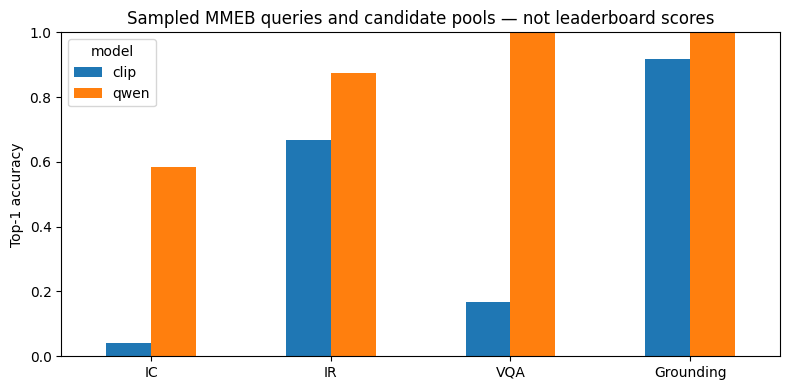

,category,model,variant,queries,top1_accuracy,MRR
0,IC,clip,full,24,0.042,0.203
1,IC,clip,image_only,24,0.542,0.662
2,IC,clip,text_only,24,0.042,0.131
3,IR,clip,full,24,0.667,0.785
4,IR,clip,image_only,24,0.500,0.679
5,IR,clip,text_only,24,0.708,0.818
6,VQA,clip,full,24,0.167,0.292
7,VQA,clip,image_only,24,0.125,0.289
8,VQA,clip,text_only,24,0.042,0.195
9,Grounding,clip,full,24,0.917,0.939


In [12]:
#@title Accuracy, MRR, and query-modality ablations
# Can be rerun after reconnecting, once configuration and data cells restore the manifest.
records = []
for name in MODEL_IDS:
    records.extend(json.loads((RUN_DIR / f'{name}_predictions.json').read_text()))
results = pd.DataFrame(records)
full = results[results.variant == 'full'].copy()
assert full.groupby('model').size().to_dict() == {name: len(examples) for name in MODEL_IDS}
summary = full.groupby(['category', 'dataset', 'model'], sort=False).agg(
    queries=('correct', 'size'), top1_accuracy=('correct', 'mean'),
    MRR=('reciprocal_rank', 'mean'), mean_candidates=('n_candidates', 'mean'),
    tied_top_scores=('top_ties', lambda x: int((x > 1).sum()))).reset_index()
summary.to_csv(RUN_DIR / 'metrics.csv', index=False)
display(summary.round(3))
print('Chance top-1 for these candidate counts:', round((1 / full.n_candidates).mean(), 4))

fig, ax = plt.subplots(figsize=(8, 4))
summary.pivot(index='category', columns='model', values='top1_accuracy').reindex(DATASETS).plot.bar(ax=ax)
ax.set(ylabel='Top-1 accuracy', xlabel='', ylim=(0, 1),
       title='Sampled MMEB queries and candidate pools — not leaderboard scores')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
fig.savefig(RUN_DIR / 'accuracy.png', dpi=160, bbox_inches='tight')
plt.show()

ablation_summary = results.groupby(['category', 'model', 'variant'], sort=False).agg(
    queries=('correct', 'size'), top1_accuracy=('correct', 'mean'), MRR=('reciprocal_rank', 'mean')).reset_index()
ablation_summary.to_csv(RUN_DIR / 'ablation_metrics.csv', index=False)
display(ablation_summary.round(3))

**Main findings.** Qwen retrieves **83/96** annotated targets (86.5%); the CLIP fusion
baseline retrieves **43/96** (44.8%). Interpretation depends on the query representation:

- **Classification:** CLIP improves from **4.2% to 54.2%** when the generic instruction
  is removed. Much of its apparent deficit therefore comes from the fusion rule.
- **CIRR:** Text-only queries outperform full queries for both models (**70.8% vs. 66.7%**
  for CLIP; **91.7% vs. 87.5%** for Qwen). Many sampled pools can be solved without the
  reference image.
- **TextVQA:** Qwen reaches **100%** with full queries, compared with **33.3%** for
  image-only and **58.3%** for text-only queries. Joint inputs help on this sample.

Each task has only 24 queries. Differences in training, model size, preprocessing, and
CLIP's fusion rule prevent attributing the entire performance gap to architecture.

## 5. Failure analysis

A failure means at least one model misses the annotated target at rank 1. Selection covers
all four task categories and both observed failure types. The recorded run contains **53
failure queries**: 40 CLIP-only failures and 13 shared failures.

Each case below pairs its saved image panel with the measured ablation table and a concise
interpretation. `rank` is the gold-target rank; `margin` is its cosine score minus the best
negative score. Compare margins within a model, not as calibrated confidence across models.

In [13]:
#@title Select failures across categories and outcomes
paired = full.pivot(index='id', columns='model', values='correct').reindex([e['id'] for e in examples])
paired['category'] = [example_by_id[i]['category'] for i in paired.index]
paired['outcome'] = ['both correct' if c and q else 'CLIP-only failure' if not c and q
                     else 'Qwen-only failure' if c and not q else 'both fail'
                     for c, q in zip(paired['clip'], paired['qwen'])]
failures = paired[paired.outcome != 'both correct'].copy()
failures.to_csv(RUN_DIR / 'failure_candidates.csv')
display(pd.crosstab(paired.category, paired.outcome))

selected = []
for category in DATASETS:
    choices = failures.index[failures.category == category].tolist()
    if choices:
        selected.append(choices[0])
for outcome in ['CLIP-only failure', 'Qwen-only failure', 'both fail']:
    if len(selected) >= N_FAILURE_CASES:
        break
    choices = [i for i in failures.index[failures.outcome == outcome] if i not in selected]
    if choices and not any(failures.loc[i, 'outcome'] == outcome for i in selected):
        selected.append(choices[0])
selected += [i for i in failures.index if i not in selected][:max(0, N_FAILURE_CASES - len(selected))]
SELECTED_CASE_IDS = selected[:N_FAILURE_CASES]  # You may replace with reviewed IDs from failure_candidates.csv.
save_json(RUN_DIR / 'selected_cases.json', SELECTED_CASE_IDS)
print(f'{len(failures)} failure queries; selected {len(SELECTED_CASE_IDS)} for analysis.')
if len(SELECTED_CASE_IDS) < 5:
    print('NOT SUBMISSION-READY: increase N_QUERIES or MAX_CANDIDATES to find at least five failures.')
display(failures.loc[SELECTED_CASE_IDS])

outcome,CLIP-only failure,both correct,both fail
category,,,
Grounding,2,22,0
IC,13,1,10
IR,5,16,3
VQA,20,4,0


53 failure queries; selected 5 for analysis.


model,clip,qwen,category,outcome
id,,,,
CIFAR-100:65,False,False,IC,both fail
CIRR:193,False,False,IR,both fail
TextVQA:33,False,True,VQA,CLIP-only failure
RefCOCO:595,False,True,Grounding,CLIP-only failure
CIFAR-100:69,False,True,IC,CLIP-only failure


In [ ]:
#@title Case visualization helpers
def result_for(case_id, model, variant='full'):
    match = results[(results.id == case_id) & (results.model == model) & (results.variant == variant)]
    assert len(match) == 1
    return match.iloc[0]

def draw_item(ax, item, title):
    ax.axis('off')
    ax.set_title(title, fontsize=10)
    if item['image']:
        ax.imshow(read_image(item['image']))
    else:
        ax.text(.5, .55, textwrap.fill(item['text'], 30), transform=ax.transAxes,
                ha='center', va='center', fontsize=12)
    if item['text'] and item['image']:
        ax.text(.5, -.04, textwrap.fill(item['text'], 38), transform=ax.transAxes,
                ha='center', va='top', fontsize=9)

def show_case(case_id):
    e = example_by_id[case_id]
    clip, qwen = result_for(case_id, 'clip'), result_for(case_id, 'qwen')
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    draw_item(axes[0], e['query'], 'Query')
    draw_item(axes[1], e['candidates'][e['gold']], f"Annotated target (index {e['gold']})")
    draw_item(axes[2], e['candidates'][int(clip.pred)], f'CLIP prediction (gold rank {clip["rank"]})')
    draw_item(axes[3], e['candidates'][int(qwen.pred)], f'Qwen prediction (gold rank {qwen["rank"]})')
    plt.tight_layout()
    figure_path = RUN_DIR / 'cases' / f"{case_id.replace(':', '_')}.png"
    figure_path.parent.mkdir(exist_ok=True)
    fig.savefig(figure_path, dpi=150, bbox_inches='tight')
    plt.show()
    display(results[results.id == case_id][['model', 'variant', 'correct', 'rank', 'margin', 'top_ties']].round(4))

### 1. CIFAR-100:65 — A near-tie and a shared failure

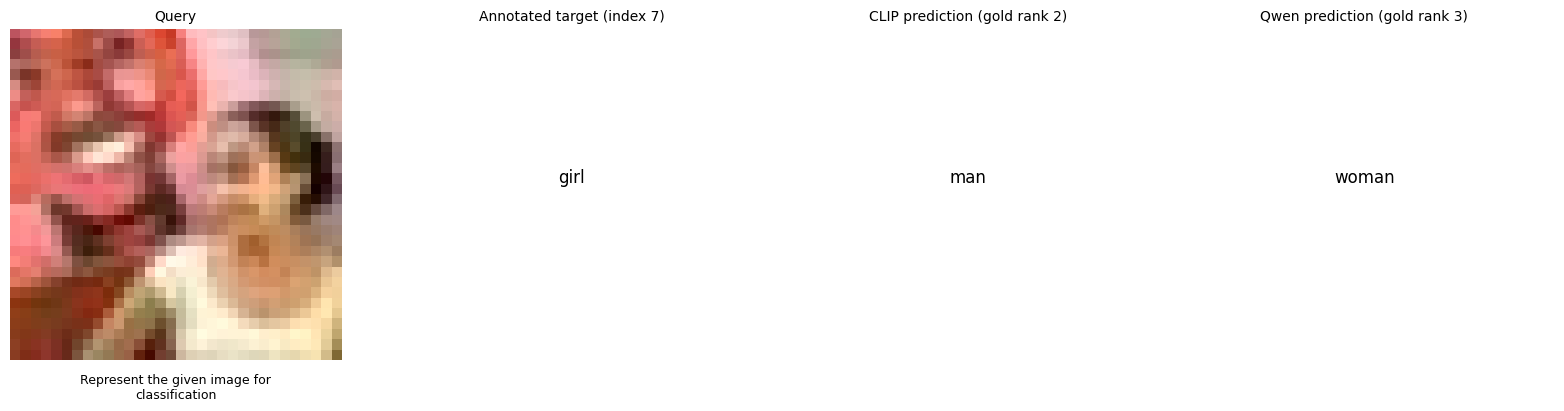

,model,variant,correct,rank,margin,top_ties
0,clip,full,False,2,-0.0005,1
1,clip,image_only,True,1,0.0002,1
2,clip,text_only,False,2,-0.0136,1
288,qwen,full,False,3,-0.0253,1
289,qwen,image_only,False,2,-0.0164,1
290,qwen,text_only,False,4,-0.0205,1


In [ ]:
#@title Saved case evidence
show_case('CIFAR-100:65')

The annotated label is **girl**; CLIP predicts **man** and Qwen predicts **woman**.
CLIP's gold rank changes from **1 to 2** when the generic instruction is added, with
a full-query margin of only **−0.0005**. The added text vector reverses an otherwise
correct image-only ranking. Qwen also worsens, from rank **2 to 3**, so joint encoding
does not guarantee robustness to the instruction. The coarse portrait offers limited
evidence for distinguishing the supplied labels; ambiguity and the near-tie limit a
strong architectural interpretation.

### 2. CIRR:193 — Only part of the edit is satisfied

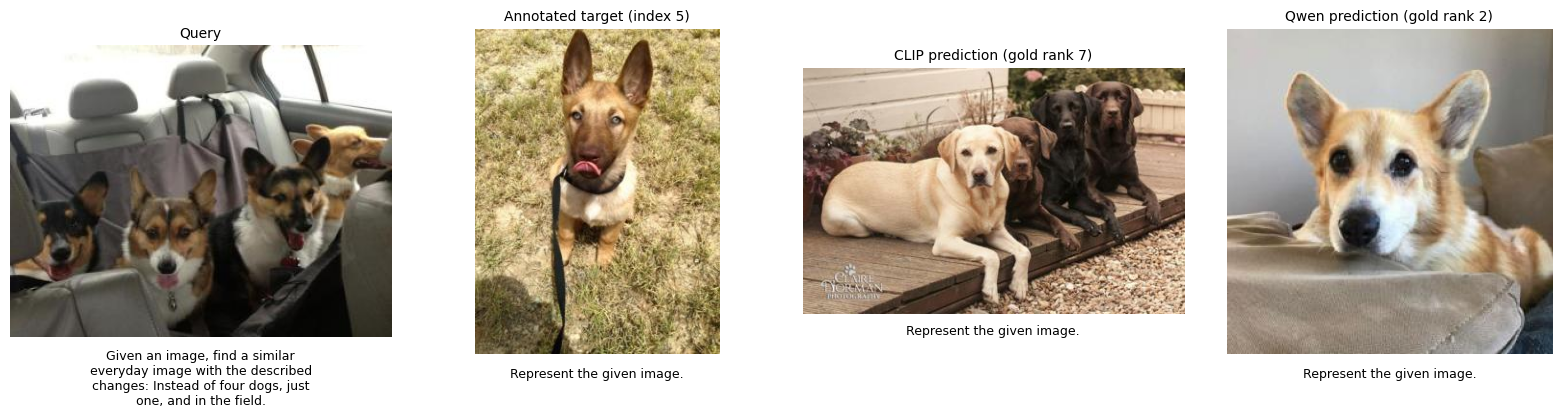

,model,variant,correct,rank,margin,top_ties
81,clip,full,False,7,-0.0522,1
82,clip,image_only,False,5,-0.0294,1
83,clip,text_only,False,15,-0.0552,1
369,qwen,full,False,2,-0.0963,1
370,qwen,image_only,False,12,-0.2690,1
371,qwen,text_only,True,1,0.0814,1


In [ ]:
#@title Saved case evidence
show_case('CIRR:193')

The query requests **one dog in a field**, replacing four dogs in a car. CLIP retrieves
several dogs on a deck, while Qwen retrieves one dog on a sofa. Their gold ranks are
**7** and **2**. Qwen satisfies the count but misses the setting; its text-only query
places the target at **rank 1**, whereas image-only ranks it **12th**. Reintroducing the
reference image reverses the text-only success. This is consistent with competing
reference-appearance and edit cues in the pooled representation, not complete attribute
binding. CLIP's result preserves broad dog-scene similarity while missing both constraints.

### 3. TextVQA:33 — Question-conditioned access to small text

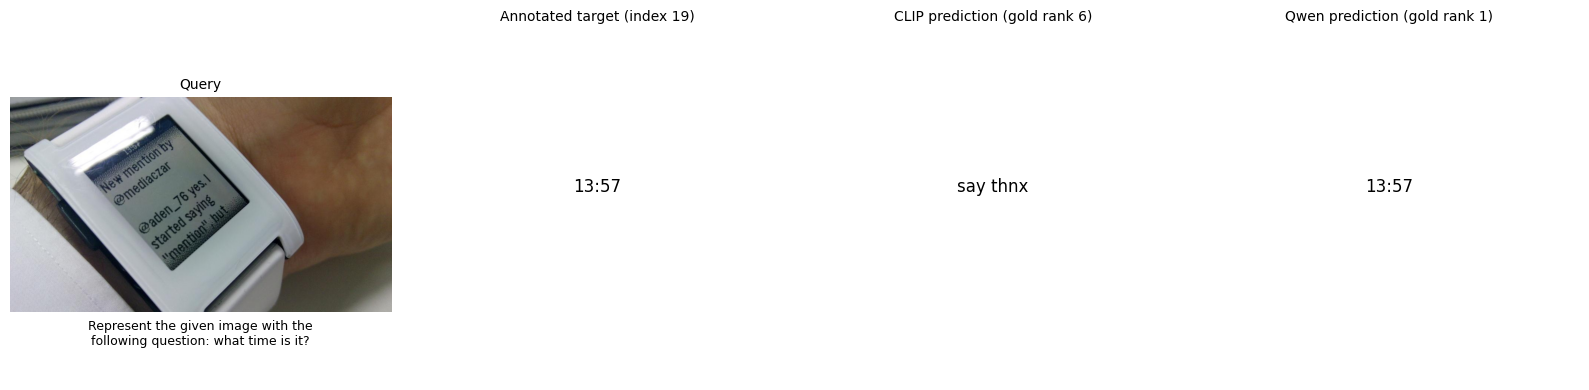

,model,variant,correct,rank,margin,top_ties
144,clip,full,False,6,-0.0126,1
145,clip,image_only,False,2,-0.0014,1
146,clip,text_only,False,12,-0.0536,1
432,qwen,full,True,1,0.1290,1
433,qwen,image_only,False,16,-0.0654,1
434,qwen,text_only,False,4,-0.0604,1


In [ ]:
#@title Saved case evidence
show_case('TextVQA:33')

The question asks the time on a smartwatch. The annotated **13:57** appears in small
text near the upper screen edge, partly affected by glare. CLIP predicts **say thnx**
(gold rank **6**); Qwen retrieves **13:57** (rank **1**). Qwen's image-only and text-only
ranks are **16** and **4**, so the combined input outperforms either modality alone.
This supports useful question-conditioned visual information before pooling. CLIP's
independent visual encoder cannot condition its features on the question. Resolution
and OCR-related training remain alternative contributors; the result does not isolate
a particular attention or reading mechanism.

### 4. RefCOCO:595 — Correct retrieval is not proof of spatial reasoning

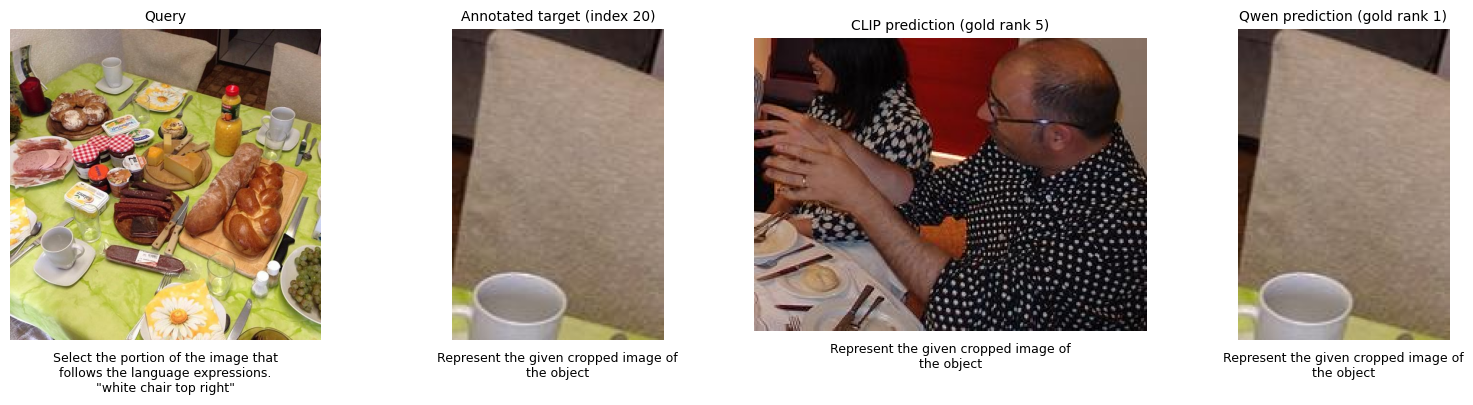

,model,variant,correct,rank,margin,top_ties
261,clip,full,False,5,-0.0228,1
262,clip,image_only,False,5,-0.0470,1
263,clip,text_only,False,2,-0.0109,1
549,qwen,full,True,1,0.2055,1
550,qwen,image_only,False,4,-0.0376,1
551,qwen,text_only,True,1,0.1543,1


In [ ]:
#@title Saved case evidence
show_case('RefCOCO:595')

For **white chair top right**, Qwen retrieves the annotated chair crop at **rank 1**;
CLIP retrieves a crop containing diners and ranks the target **5th**. CLIP's behavior
is consistent with global scene similarity outweighing the requested object. However,
Qwen also succeeds with **text alone**; its image-only gold rank is **4**. The crop can
match the description directly among these negatives. This supports language-to-crop
matching, but does not demonstrate that Qwen resolved **top right** within the query scene.

### 5. CIFAR-100:69 — Visual recognition lost through fusion

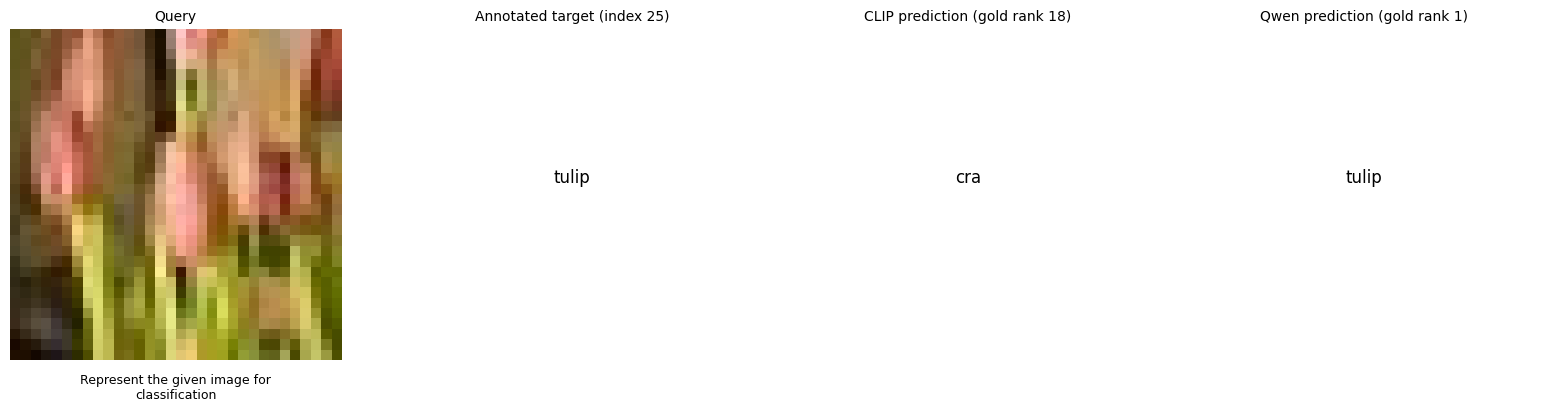

,model,variant,correct,rank,margin,top_ties
3,clip,full,False,18,-0.0816,1
4,clip,image_only,True,1,0.0286,1
5,clip,text_only,False,31,-0.1774,1
291,qwen,full,True,1,0.2174,1
292,qwen,image_only,True,1,0.0925,1
293,qwen,text_only,False,13,-0.0833,1


In [ ]:
#@title Saved case evidence
show_case('CIFAR-100:69')

The image shows pink flowers and green stems; the target label is **tulip**. CLIP's
image-only query ranks it **1st**, but equal-weight text fusion drops it to **18th**
and predicts the dataset's literal label **cra**. Its gold margin changes from
**+0.0286 to −0.0816**. Qwen ranks **tulip** first with or without query text.
The CLIP image embedding already identifies the target, so inadequate visual detail
does not explain this failure. The generic instruction distorts its ranking through
late fusion. The unusual candidate wording is retained as supplied and is another
possible confounder.

## 6. Conclusions and export

Qwen wins more full-query rankings, but the ablations reveal two important limits:
CLIP's generic-text fusion can obscure correct visual recognition, and a correct
multimodal retrieval may be solvable without the query image. The TextVQA case offers
more direct evidence of useful joint conditioning because neither modality alone
retrieves the target first.

These selected cases explain failures, not their prevalence. A follow-up should vary
CLIP's fusion weight and use harder same-scene grounding candidates. Those experiments
were not run. The LaTeX report summarizes the recorded results and these interpretations.

In [ ]:
#@title Export measured results and figures
# Written interpretations are preserved in this notebook; exclude obsolete draft-note files.
export_path = RUN_DIR.parent / f'{RUN_DIR.name}_results.zip'
evidence_files = {
    'config.json', 'sample_manifest.json', 'environment.json', 'corpus.json',
    'clip_predictions.json', 'qwen_predictions.json', 'predictions.csv',
    'metrics.csv', 'ablation_metrics.csv', 'failure_candidates.csv',
    'selected_cases.json', 'timings.json', 'clip_truncated_texts.json', 'accuracy.png',
}
with zipfile.ZipFile(export_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in RUN_DIR.rglob('*'):
        relative = path.relative_to(RUN_DIR)
        if path.is_file() and (str(relative) in evidence_files or
                              (relative.parts[0] == 'cases' and path.suffix == '.png')):
            archive.write(path, arcname=str(relative))
print('Results bundle:', export_path)

## References

1. Jiang et al. [VLM2Vec / MMEB](https://arxiv.org/abs/2410.05160), 2024.
   [Evaluation data](https://huggingface.co/datasets/TIGER-Lab/MMEB-eval).
2. Radford et al. [Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020), 2021.
3. Li et al. [Qwen3-VL-Embedding and Qwen3-VL-Reranker](https://arxiv.org/abs/2601.04720), 2026.
   [Pinned embedding implementation](https://github.com/QwenLM/Qwen3-VL-Embedding/blob/393e2978d27852b0d0230d6994f37f9c15bed73c/src/models/qwen3_vl_embedding.py).